### 1. What is NER

NER is stand for Named Entity Recognition. NER is an NLP technique used to identify and classify named entities in *text*.

In [1]:
# Install SpaCy
!pip install spacy

In [2]:
# Download the English model:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 43.3 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [3]:
# 1. Basic NER
import spacy
nlp = spacy.load("en_core_web_sm")
text = "Apple is headquartered in colifornia."
doc = nlp(text)

for ent in doc.ents:
  print(ent.text, ent.label_)

Apple ORG
colifornia GPE


In [4]:
# 2. Person Identification
import spacy
nlp = spacy.load("en_core_web_sm")
text = "Elon Musk is the CEO of Tesla"
doc = nlp(text)

for ent in doc.ents:
  print(ent.text, ent.label_)

Elon Musk PERSON
Tesla ORG


In [5]:
# 3. Organizations
import spacy
nlp = spacy.load("en_core_web_sm")
text = "Google and Microsoft are technology companies."
doc = nlp(text)

for ent in doc.ents:
  print(ent.text, ent.label_)

Google ORG
Microsoft ORG


In [6]:
# 4. Locations
import spacy
nlp = spacy.load("en_core_web_sm")
text = "India is located in South Asia."
doc = nlp(text)

for ent in doc.ents:
  print(ent.text, ent.label_)

India GPE
South Asia LOC


In [7]:
# 5. Dates
import spacy
nlp = spacy.load("en_core_web_sm")
text = "The conference will be held on 15 September 2026."
doc = nlp(text)

for ent in doc.ents:
  print(ent.text, ent.label_)

15 September 2026 DATE


In [8]:
# 6. Money
import spacy
nlp = spacy.load("en_core_web_sm")
text = "The company invested $5 million in the project"
doc = nlp(text)
for ent in doc.ents:
  print(ent.text, ent.label_)

$5 million MONEY


In [9]:
# 7. Percentage
import spacy
nlp = spacy.load("en_core_web_sm")
text = "The company reported a 25% increase in revenue."
doc = nlp(text)
for ent in doc.ents:
  print(ent.text, ent.label_)

25% PERCENT


In [10]:
# 8. Extract Only PERSON Entities
import spacy
nlp = spacy.load("en_core_web_sm")
text = """
Sundar Pichai is the CEO of Google.
Satya Nadella is the CEO of Microsoft.
"""
doc = nlp(text)

for ent in doc.ents:
  if ent.label_ == "PERSON":
    print(ent.text)

Sundar Pichai
Satya Nadella


In [11]:
# 9. Extract Organizations
import spacy
nlp = spacy.load("en_core_web_sm")
text = """
Google developed several AI products.
Microsoft also invests heavily in artificial intelligence.
"""
doc = nlp(text)

for ent in doc.ents:
  if ent.label_ == "ORG":
    print(ent.text)

Google
AI
Microsoft


In [12]:
# 10. Extract All Entity Types
import spacy
nlp = spacy.load("en_core_web_sm")
text = """
Ratan Tata visited London on 10 January 2025.
He donated 50 crore to be charitable organization.
"""
doc = nlp(text)

for ent in doc.ents:
  print(
      "Entity:", ent.text,
      "| Label:", ent.label_,
      "| Meaning:", spacy.explain(ent.label_)
  )

Entity: Ratan Tata | Label: ORG | Meaning: Companies, agencies, institutions, etc.
Entity: London | Label: GPE | Meaning: Countries, cities, states
Entity: 10 January 2025 | Label: DATE | Meaning: Absolute or relative dates or periods
Entity: 50 | Label: CARDINAL | Meaning: Numerals that do not fall under another type


In [13]:
# 11. NER Visualization with displaCy
import spacy
from spacy import displacy
nlp = spacy.load("en_core_web_sm")
text = "Sundar Pichai is the CEO of Google in California."

doc = nlp(text)

displacy.render(
    doc,
    style="ent",
    jupyter=True
)

Counter({'ORG': 3, 'PERSON': 3, 'GPE': 1})


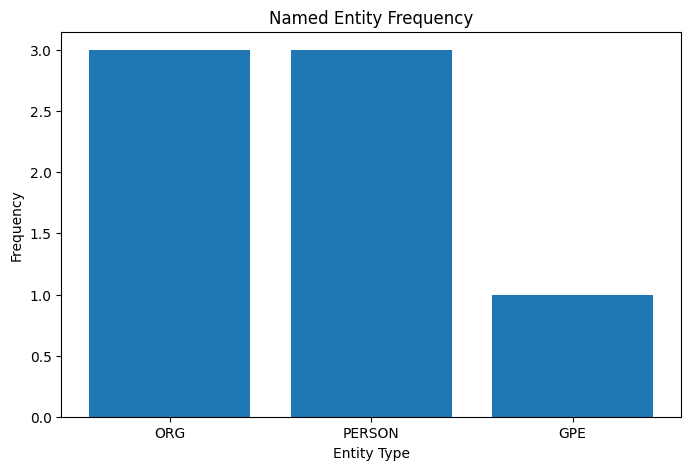

In [14]:
# 12. NER Frequency Visualization
import spacy
from collections import Counter
import matplotlib.pyplot as plt

nlp = spacy.load("en_core_web_sm")

text = """
Google was founded by Larry Page Sergey Brin.
Microsoft was founded by Bill Gates.
Apple was founded by Steve Jobs.
These companies are based in the united States.
"""
doc = nlp(text)

entity_counts = Counter(
    ent.label_ for ent in doc.ents
)
print(entity_counts)

plt.figure(figsize=(8, 5))
plt.bar(
    entity_counts.keys(),
    entity_counts.values()
)

plt.xlabel("Entity Type")
plt.ylabel("Frequency")
plt.title("Named Entity Frequency")

plt.show()

In [19]:
# 13. Create an NER DataFrame
import spacy
import pandas as pd

nlp = spacy.load("en_core_web_sm")

text = """
Elon Musk founded SpaceX.
Sundar Pichai leads Google.
Satya Nadella leads Microsoft.
"""
doc = nlp(text)

data = []

for ent in doc.ents:
  data.append({
      "Entity": ent.text,
      "Label": ent.label_,
      "Description": spacy.explain(ent.label_)
  })

df = pd.DataFrame(data)
print(df)

          Entity   Label                              Description
0      Elon Musk  PERSON              People, including fictional
1  Sundar Pichai  PERSON              People, including fictional
2         Google     ORG  Companies, agencies, institutions, etc.
3  Satya Nadella  PERSON              People, including fictional
4      Microsoft     ORG  Companies, agencies, institutions, etc.


Named Entities
----------------------------------------
Sundar Pichai       PERSON    People, including fictional
Google              ORG       Companies, agencies, institutions, etc.
Satya Nadella       PERSON    People, including fictional
Microsoft           ORG       Companies, agencies, institutions, etc.
Elon Musk           PERSON    People, including fictional
Google              ORG       Companies, agencies, institutions, etc.
Microsoft           ORG       Companies, agencies, institutions, etc.
the United States   GPE       Countries, cities, states

Entity Frequency:
Counter({'ORG': 4, 'PERSON': 3, 'GPE': 1})


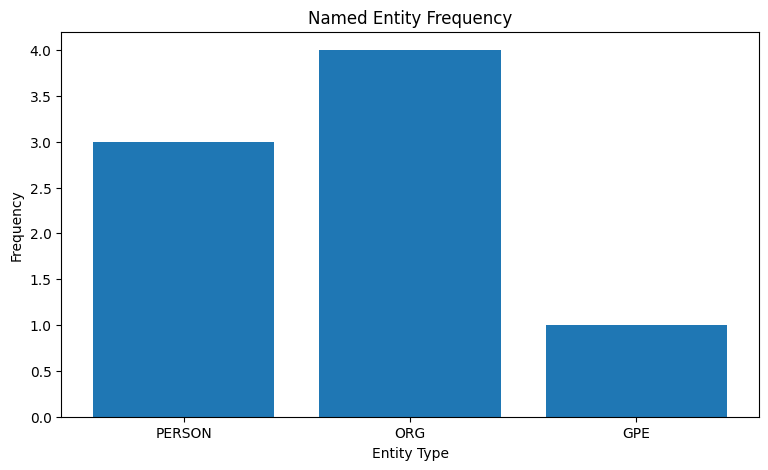

In [20]:
# Complete NER Program with Visualization
# This combines NER extraction + frequency analysis + visualization + displaCy:
import spacy
from collections import Counter
import matplotlib.pyplot as plt
from spacy import displacy

# Text
text = """
Sundar Pichai is the CEO of Google.
Satya Nadella is the CEO of Microsoft.
Elon Musk founded SpaceX.
Google and Microsoft are based in the United States.
"""

# Process text
doc = nlp(text)

# Display entities
print("Named Entities")
print("-"*40)

for ent in doc.ents:
  print(
      f"{ent.text:20}"
      f"{ent.label_:10}"
      f"{spacy.explain(ent.label_)}"
  )

# Count entity types
entity_counts = Counter(
    ent.label_ for ent in doc.ents
)

print("\nEntity Frequency:")
print(entity_counts)

# Bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    entity_counts.keys(),
    entity_counts.values()
)

plt.xlabel("Entity Type")
plt.ylabel("Frequency")
plt.title("Named Entity Frequency")

plt.show()

# Entity visualization
displacy.render(
    doc,
    style="ent",
    jupyter=True
)